# Analyse RH — jointure, statistiques descriptives et visualisations

Objectif du notebook :

1. Charger les trois fichiers de départ : SIRH, évaluations et sondage.
2. Construire un **DataFrame central** par jointure sur l'identifiant employé.
3. Produire des statistiques descriptives sur chaque fichier puis sur le fichier central.
4. Générer des graphiques pour faire ressortir des différences clés entre les employés, notamment selon le fait d'avoir quitté l'entreprise ou non.


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")


## 1. Chargement des fichiers

Le code ci-dessous fonctionne si les fichiers CSV sont dans le même dossier que le notebook.  
Il prévoit aussi le cas où le notebook est exécuté dans l'environnement `/mnt/data`.


In [3]:
DATA_DIR = Path(".")

fichiers = {
    "sirh": DATA_DIR / "extrait_sirh.csv",
    "eval": DATA_DIR / "extrait_eval.csv",
    "sondage": DATA_DIR / "extrait_sondage.csv",
}

# Fallback pour l'environnement 
if not all(path.exists() for path in fichiers.values()):
    DATA_DIR = Path("/mnt/data")
    fichiers = {
        "sirh": DATA_DIR / "extrait_sirh.csv",
        "eval": DATA_DIR / "extrait_eval.csv",
        "sondage": DATA_DIR / "extrait_sondage.csv",
    }

df_sirh = pd.read_csv(fichiers["sirh"])
df_eval = pd.read_csv(fichiers["eval"])
df_sondage = pd.read_csv(fichiers["sondage"])

print("SIRH :", df_sirh.shape)
print("Évaluations :", df_eval.shape)
print("Sondage :", df_sondage.shape)

display(df_sirh.head())
display(df_eval.head())
display(df_sondage.head())


SIRH : (1470, 12)
Évaluations : (1470, 10)
Sondage : (1470, 12)


,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2


,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,2,3,2,4,1,1,E_1,3,Oui,11 %
1,3,2,2,2,4,3,E_2,4,Non,23 %
2,4,2,1,3,2,3,E_4,3,Oui,15 %
3,4,3,1,3,3,3,E_5,3,Oui,11 %
4,1,3,1,2,4,3,E_7,3,Non,12 %


,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,Oui,0,0,1,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,Non,1,3,1,2,8,1,Infra & Cloud,Y,Frequent,1,7
2,Oui,0,3,1,4,2,2,Autre,Y,Occasionnel,0,0
3,Non,0,3,1,5,3,4,Infra & Cloud,Y,Frequent,3,0
4,Non,1,3,1,7,2,1,Transformation Digitale,Y,Occasionnel,2,2


## 2. Contrôle rapide des fichiers de départ

Cette étape permet de documenter les fichiers avant jointure : dimensions, types, valeurs manquantes et doublons éventuels.


In [4]:
def resume_fichier(df: pd.DataFrame, nom: str) -> pd.DataFrame:
    """Résumé technique d'un fichier de départ."""
    resume = pd.DataFrame({
        "colonne": df.columns,
        "type": df.dtypes.astype(str).values,
        "nb_valeurs_manquantes": df.isna().sum().values,
        "taux_valeurs_manquantes_%": (df.isna().mean() * 100).round(2).values,
        "nb_valeurs_uniques": df.nunique(dropna=False).values,
    })
    print(f"\n===== {nom} =====")
    print(f"Dimensions : {df.shape[0]} lignes x {df.shape[1]} colonnes")
    display(resume)
    return resume

resume_sirh = resume_fichier(df_sirh, "SIRH")
resume_eval = resume_fichier(df_eval, "Évaluations")
resume_sondage = resume_fichier(df_sondage, "Sondage")



===== SIRH =====
Dimensions : 1470 lignes x 12 colonnes


,colonne,type,nb_valeurs_manquantes,taux_valeurs_manquantes_%,nb_valeurs_uniques
0,id_employee,int64,0,0.0,1470
1,age,int64,0,0.0,43
2,genre,str,0,0.0,2
3,revenu_mensuel,int64,0,0.0,1349
4,statut_marital,str,0,0.0,3
5,departement,str,0,0.0,3
6,poste,str,0,0.0,9
7,nombre_experiences_precedentes,int64,0,0.0,10
8,nombre_heures_travailless,int64,0,0.0,1
9,annee_experience_totale,int64,0,0.0,40



===== Évaluations =====
Dimensions : 1470 lignes x 10 colonnes


,colonne,type,nb_valeurs_manquantes,taux_valeurs_manquantes_%,nb_valeurs_uniques
0,satisfaction_employee_environnement,int64,0,0.0,4
1,note_evaluation_precedente,int64,0,0.0,4
2,niveau_hierarchique_poste,int64,0,0.0,5
3,satisfaction_employee_nature_travail,int64,0,0.0,4
4,satisfaction_employee_equipe,int64,0,0.0,4
5,satisfaction_employee_equilibre_pro_perso,int64,0,0.0,4
6,eval_number,str,0,0.0,1470
7,note_evaluation_actuelle,int64,0,0.0,2
8,heure_supplementaires,str,0,0.0,2
9,augementation_salaire_precedente,str,0,0.0,15



===== Sondage =====
Dimensions : 1470 lignes x 12 colonnes


,colonne,type,nb_valeurs_manquantes,taux_valeurs_manquantes_%,nb_valeurs_uniques
0,a_quitte_l_entreprise,str,0,0.0,2
1,nombre_participation_pee,int64,0,0.0,4
2,nb_formations_suivies,int64,0,0.0,7
3,nombre_employee_sous_responsabilite,int64,0,0.0,1
4,code_sondage,int64,0,0.0,1470
5,distance_domicile_travail,int64,0,0.0,29
6,niveau_education,int64,0,0.0,5
7,domaine_etude,str,0,0.0,6
8,ayant_enfants,str,0,0.0,1
9,frequence_deplacement,str,0,0.0,3


In [5]:
# Statistiques descriptives numériques des fichiers de départ
display(df_sirh.describe().T)
display(df_eval.describe().T)
display(df_sondage.describe().T)


,count,mean,std,min,25%,50%,75%,max
id_employee,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
revenu_mensuel,1470.0,6502.931293,4707.956783,1009.0,2911.00,4919.0,8379.00,19999.0
nombre_experiences_precedentes,1470.0,2.693197,2.498009,0.0,1.00,2.0,4.00,9.0
nombre_heures_travailless,1470.0,80.000000,0.000000,80.0,80.00,80.0,80.00,80.0
annee_experience_totale,1470.0,11.279592,7.780782,0.0,6.00,10.0,15.00,40.0
annees_dans_l_entreprise,1470.0,7.008163,6.126525,0.0,3.00,5.0,9.00,40.0
annees_dans_le_poste_actuel,1470.0,4.229252,3.623137,0.0,2.00,3.0,7.00,18.0


,count,mean,std,min,25%,50%,75%,max
satisfaction_employee_environnement,1470.0,2.721769,1.093082,1.0,2.0,3.0,4.0,4.0
note_evaluation_precedente,1470.0,2.729932,0.711561,1.0,2.0,3.0,3.0,4.0
niveau_hierarchique_poste,1470.0,2.063946,1.106940,1.0,1.0,2.0,3.0,5.0
satisfaction_employee_nature_travail,1470.0,2.728571,1.102846,1.0,2.0,3.0,4.0,4.0
satisfaction_employee_equipe,1470.0,2.712245,1.081209,1.0,2.0,3.0,4.0,4.0
satisfaction_employee_equilibre_pro_perso,1470.0,2.761224,0.706476,1.0,2.0,3.0,3.0,4.0
note_evaluation_actuelle,1470.0,3.153741,0.360824,3.0,3.0,3.0,3.0,4.0


,count,mean,std,min,25%,50%,75%,max
nombre_participation_pee,1470.0,0.793878,0.852077,0.0,0.00,1.0,1.00,3.0
nb_formations_suivies,1470.0,2.799320,1.289271,0.0,2.00,3.0,3.00,6.0
nombre_employee_sous_responsabilite,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
code_sondage,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
distance_domicile_travail,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
niveau_education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
annees_depuis_la_derniere_promotion,1470.0,2.187755,3.222430,0.0,0.00,1.0,3.00,15.0
annes_sous_responsable_actuel,1470.0,4.123129,3.568136,0.0,2.00,3.0,7.00,17.0


In [5]:
# Statistiques descriptives catégorielles des fichiers de départ
display(df_sirh.describe(include="object").T)
display(df_eval.describe(include="object").T)
display(df_sondage.describe(include="object").T)


C:\Users\johnd\AppData\Local\Temp\ipykernel_25824\3035723815.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df_sirh.describe(include="object").T)


,count,unique,top,freq
genre,1470,2,M,882
statut_marital,1470,3,Marié(e),673
departement,1470,3,Consulting,961
poste,1470,9,Cadre Commercial,326


C:\Users\johnd\AppData\Local\Temp\ipykernel_25824\3035723815.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df_eval.describe(include="object").T)


,count,unique,top,freq
eval_number,1470,1470,E_1,1
heure_supplementaires,1470,2,Non,1054
augementation_salaire_precedente,1470,15,11 %,210


C:\Users\johnd\AppData\Local\Temp\ipykernel_25824\3035723815.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df_sondage.describe(include="object").T)


,count,unique,top,freq
a_quitte_l_entreprise,1470,2,Non,1233
domaine_etude,1470,6,Infra & Cloud,606
ayant_enfants,1470,1,Y,1470
frequence_deplacement,1470,3,Occasionnel,1043


## 3. Préparation des clés de jointure

Les fichiers n'utilisent pas exactement le même nom de clé :

- `df_sirh` contient `id_employee`.
- `df_eval` contient `eval_number`, sous la forme `E_1`, `E_2`, etc.
- `df_sondage` contient `code_sondage`.

On extrait donc l'identifiant numérique depuis `eval_number`, puis on renomme `code_sondage`.


In [6]:
# Extraction de l'id employé depuis eval_number : "E_123" -> 123
df_eval = df_eval.copy()
df_eval["id_employee"] = (
    df_eval["eval_number"]
    .astype(str)
    .str.extract(r"(\d+)")
    .astype(int)
)

# Harmonisation de la clé de jointure du sondage
df_sondage = df_sondage.copy()
df_sondage = df_sondage.rename(columns={"code_sondage": "id_employee"})

# Conversion du pourcentage d'augmentation salariale en numérique
df_eval["augmentation_salaire_precedente_pct"] = (
    df_eval["augementation_salaire_precedente"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .str.strip()
    .astype(float)
)

# Contrôle d'unicité des clés
cles = {
    "SIRH": df_sirh["id_employee"],
    "Évaluations": df_eval["id_employee"],
    "Sondage": df_sondage["id_employee"],
}

for nom, serie in cles.items():
    print(f"{nom} — clé unique :", serie.is_unique, "| doublons :", serie.duplicated().sum())


SIRH — clé unique : True | doublons : 0
Évaluations — clé unique : True | doublons : 0
Sondage — clé unique : True | doublons : 0


In [7]:
# Contrôle de cohérence des identifiants entre fichiers
ids_sirh = set(df_sirh["id_employee"])
ids_eval = set(df_eval["id_employee"])
ids_sondage = set(df_sondage["id_employee"])

print("Ids SIRH absents des évaluations :", len(ids_sirh - ids_eval))
print("Ids SIRH absents du sondage :", len(ids_sirh - ids_sondage))
print("Ids évaluations absents du SIRH :", len(ids_eval - ids_sirh))
print("Ids sondage absents du SIRH :", len(ids_sondage - ids_sirh))


Ids SIRH absents des évaluations : 0
Ids SIRH absents du sondage : 0
Ids évaluations absents du SIRH : 0
Ids sondage absents du SIRH : 0


## 4. Création du DataFrame central

La jointure est faite en `inner join` car les trois fichiers ont le même nombre de lignes et les mêmes identifiants.  
Le paramètre `validate="one_to_one"` sécurise la jointure : il déclenche une erreur si une clé est dupliquée dans l'un des fichiers.


In [8]:
df_central = (
    df_sirh
    .merge(df_eval, on="id_employee", how="inner", validate="one_to_one")
    .merge(df_sondage, on="id_employee", how="inner", validate="one_to_one")
)

print("Dimensions du DataFrame central :", df_central.shape)
print("Nombre de doublons sur id_employee :", df_central["id_employee"].duplicated().sum())
print("Nombre total de valeurs manquantes :", df_central.isna().sum().sum())

display(df_central.head())


Dimensions du DataFrame central : (1470, 34)
Nombre de doublons sur id_employee : 0
Nombre total de valeurs manquantes : 0


,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente,augmentation_salaire_precedente_pct,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4,2,3,2,4,1,1,E_1,3,Oui,11 %,11.0,Oui,0,0,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7,3,2,2,2,4,3,E_2,4,Non,23 %,23.0,Non,1,3,1,8,1,Infra & Cloud,Y,Frequent,1,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0,4,2,1,3,2,3,E_4,3,Oui,15 %,15.0,Oui,0,3,1,2,2,Autre,Y,Occasionnel,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7,4,3,1,3,3,3,E_5,3,Oui,11 %,11.0,Non,0,3,1,3,4,Infra & Cloud,Y,Frequent,3,0
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2,1,3,1,2,4,3,E_7,3,Non,12 %,12.0,Non,1,3,1,2,1,Transformation Digitale,Y,Occasionnel,2,2


In [9]:
# Sauvegarde optionnelle du fichier central
df_central.to_csv("df_central_rh.csv", index=False)


## 5. Statistiques descriptives du DataFrame central

On distingue :

- les variables numériques ;
- les variables catégorielles ;
- les comparaisons selon la variable `a_quitte_l_entreprise`.


In [10]:
# Vue globale
display(df_central.info())
display(df_central.describe(include="all").T)


<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 34 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   id_employee                                1470 non-null   int64  
 1   age                                        1470 non-null   int64  
 2   genre                                      1470 non-null   str    
 3   revenu_mensuel                             1470 non-null   int64  
 4   statut_marital                             1470 non-null   str    
 5   departement                                1470 non-null   str    
 6   poste                                      1470 non-null   str    
 7   nombre_experiences_precedentes             1470 non-null   int64  
 8   nombre_heures_travailless                  1470 non-null   int64  
 9   annee_experience_totale                    1470 non-null   int64  
 10  annees_dans_l_entreprise           

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_employee,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
genre,1470,2,M,882,NaN,NaN,NaN,NaN,NaN,NaN,NaN
revenu_mensuel,1470.0,NaN,NaN,NaN,6502.931293,4707.956783,1009.0,2911.0,4919.0,8379.0,19999.0
statut_marital,1470,3,Marié(e),673,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departement,1470,3,Consulting,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
poste,1470,9,Cadre Commercial,326,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nombre_experiences_precedentes,1470.0,NaN,NaN,NaN,2.693197,2.498009,0.0,1.0,2.0,4.0,9.0
nombre_heures_travailless,1470.0,NaN,NaN,NaN,80.0,0.0,80.0,80.0,80.0,80.0,80.0
annee_experience_totale,1470.0,NaN,NaN,NaN,11.279592,7.780782,0.0,6.0,10.0,15.0,40.0


In [11]:
# Répartition de la cible : employés ayant quitté ou non l'entreprise
repartition_attrition = (
    df_central["a_quitte_l_entreprise"]
    .value_counts()
    .to_frame("effectif")
    .assign(pourcentage=lambda x: (x["effectif"] / x["effectif"].sum() * 100).round(2))
)

display(repartition_attrition)


,effectif,pourcentage
a_quitte_l_entreprise,,
Non,1233,83.88
Oui,237,16.12


In [12]:
# Comparaison des variables numériques selon le départ de l'entreprise
colonnes_numeriques = df_central.select_dtypes(include=np.number).columns.drop("id_employee")

stats_par_attrition = (
    df_central
    .groupby("a_quitte_l_entreprise")[colonnes_numeriques]
    .agg(["mean", "median", "std"])
    .round(2)
    .T
)

display(stats_par_attrition)


a_quitte_l_entreprise                                 Non      Oui
age                                       mean      37.56    33.61
                                          median    36.00    32.00
                                          std        8.89     9.69
revenu_mensuel                            mean    6832.74  4787.09
                                          median  5204.00  3202.00
                                          std     4818.21  3640.21
nombre_experiences_precedentes            mean       2.65     2.94
                                          median     2.00     1.00
                                          std        2.46     2.68
nombre_heures_travailless                 mean      80.00    80.00
                                          median    80.00    80.00
                                          std        0.00     0.00
annee_experience_totale                   mean      11.86     8.24
                                          median    10.00     7.00
                                          std        7.76     7.17
annees_dans_l_entreprise                  mean       7.37     5.13
                                          median     6.00     3.00
                                          std        6.10     5.95
annees_dans_le_poste_actuel               mean       4.48     2.90
                                          median     3.00     2.00
                                          std        3.65     3.17
satisfaction_employee_environnement       mean       2.77     2.46
                                          median     3.00     3.00
                                          std        1.07     1.17
note_evaluation_precedente                mean       2.77     2.52
                                          median     3.00     3.00
                                          std        0.69     0.77
niveau_hierarchique_poste                 mean       2.15     1.64
                                          median     2.00     1.00
                                          std        1.12     0.94
satisfaction_employee_nature_travail      mean       2.78     2.47
                                          median     3.00     3.00
                                          std        1.09     1.12
satisfaction_employee_equipe              mean       2.73     2.60
                                          median     3.00     3.00
                                          std        1.07     1.13
satisfaction_employee_equilibre_pro_perso mean       2.78     2.66
                                          median     3.00     3.00
                                          std        0.68     0.82
note_evaluation_actuelle                  mean       3.15     3.16
                                          median     3.00     3.00
                                          std        0.36     0.36
augmentation_salaire_precedente_pct       mean      15.23    15.10
                                          median    14.00    14.00
                                          std        3.64     3.77
nombre_participation_pee                  mean       0.85     0.53
                                          median     1.00     0.00
                                          std        0.84     0.86
nb_formations_suivies                     mean       2.83     2.62
                                          median     3.00     2.00
                                          std        1.29     1.25
nombre_employee_sous_responsabilite       mean       1.00     1.00
                                          median     1.00     1.00
                                          std        0.00     0.00
distance_domicile_travail                 mean       8.92    10.63
                                          median     7.00     9.00
                                          std        8.01     8.45
niveau_education                          mean       2.93     2.84
                                          media

In [13]:
# Tableau synthétique des écarts de moyenne entre employés partis et restés
moyennes = df_central.groupby("a_quitte_l_entreprise")[colonnes_numeriques].mean().T

comparaison_moyennes = (
    moyennes
    .assign(ecart_oui_moins_non=moyennes["Oui"] - moyennes["Non"])
    .assign(ecart_absolu=lambda x: x["ecart_oui_moins_non"].abs())
    .sort_values("ecart_absolu", ascending=False)
    .drop(columns="ecart_absolu")
    .round(2)
)

display(comparaison_moyennes.head(20))


a_quitte_l_entreprise,Non,Oui,ecart_oui_moins_non
revenu_mensuel,6832.74,4787.09,-2045.65
age,37.56,33.61,-3.95
annee_experience_totale,11.86,8.24,-3.62
annees_dans_l_entreprise,7.37,5.13,-2.24
distance_domicile_travail,8.92,10.63,1.72
annees_dans_le_poste_actuel,4.48,2.90,-1.58
annes_sous_responsable_actuel,4.37,2.85,-1.52
niveau_hierarchique_poste,2.15,1.64,-0.51
nombre_participation_pee,0.85,0.53,-0.32
satisfaction_employee_nature_travail,2.78,2.47,-0.31


In [14]:
# Comparaison des variables catégorielles : taux de départ par modalité
def taux_depart_par_modalite(df: pd.DataFrame, colonne: str) -> pd.DataFrame:
    table = (
        pd.crosstab(df[colonne], df["a_quitte_l_entreprise"], normalize="index")
        .mul(100)
        .round(2)
    )
    if "Oui" in table.columns:
        table = table.sort_values("Oui", ascending=False)
    return table

variables_categorielles = [
    "genre",
    "statut_marital",
    "departement",
    "poste",
    "heure_supplementaires",
    "domaine_etude",
    "frequence_deplacement",
]

for col in variables_categorielles:
    print(f"\nTaux de départ par {col}")
    display(taux_depart_par_modalite(df_central, col))



Taux de départ par genre


a_quitte_l_entreprise,Non,Oui
genre,,
M,82.99,17.01
F,85.20,14.80



Taux de départ par statut_marital


a_quitte_l_entreprise,Non,Oui
statut_marital,,
Célibataire,74.47,25.53
Marié(e),87.52,12.48
Divorcé(e),89.91,10.09



Taux de départ par departement


...

a_quitte_l_entreprise,Non,Oui
heure_supplementaires,,
Oui,69.47,30.53
Non,89.56,10.44



Taux de départ par domaine_etude


a_quitte_l_entreprise,Non,Oui
domaine_etude,,
Ressources Humaines,74.07,25.93
Entrepreunariat,75.76,24.24
Marketing,77.99,22.01
Infra & Cloud,85.31,14.69
Transformation Digitale,86.42,13.58
Autre,86.59,13.41



Taux de départ par frequence_deplacement


a_quitte_l_entreprise,Non,Oui
frequence_deplacement,,
Frequent,75.09,24.91
Occasionnel,85.04,14.96
Aucun,92.00,8.00


## 6. Graphiques — différences clés entre les employés

Les graphiques ci-dessous se concentrent sur la comparaison entre les employés ayant quitté l'entreprise et ceux qui sont restés.


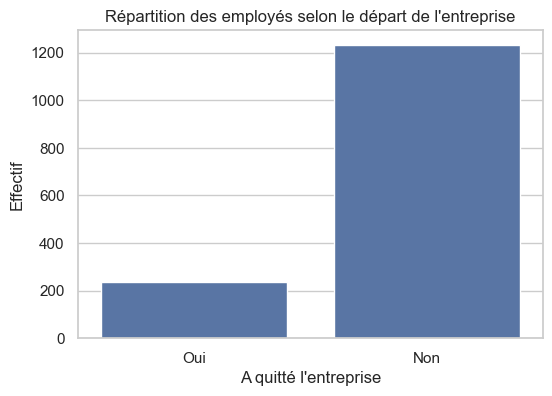

In [15]:
# Graphique 1 — Répartition des employés partis/restés
plt.figure(figsize=(6, 4))
sns.countplot(data=df_central, x="a_quitte_l_entreprise")
plt.title("Répartition des employés selon le départ de l'entreprise")
plt.xlabel("A quitté l'entreprise")
plt.ylabel("Effectif")
plt.show()


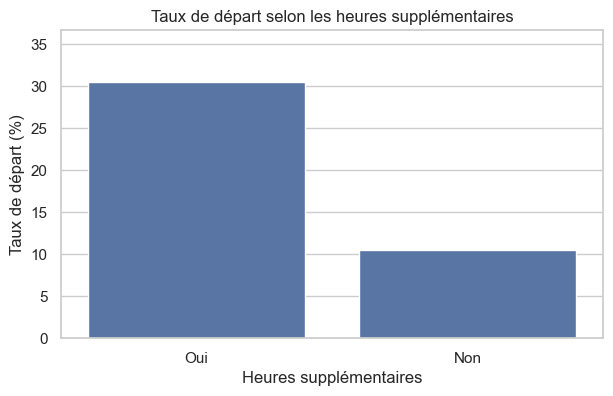

a_quitte_l_entreprise,heure_supplementaires,Non,Oui
0,Oui,69.47,30.53
1,Non,89.56,10.44


In [16]:
# Graphique 2 — Taux de départ selon les heures supplémentaires
taux_overtime = taux_depart_par_modalite(df_central, "heure_supplementaires").reset_index()

plt.figure(figsize=(7, 4))
sns.barplot(data=taux_overtime, x="heure_supplementaires", y="Oui")
plt.title("Taux de départ selon les heures supplémentaires")
plt.xlabel("Heures supplémentaires")
plt.ylabel("Taux de départ (%)")
plt.ylim(0, max(taux_overtime["Oui"]) * 1.2)
plt.show()

display(taux_overtime)


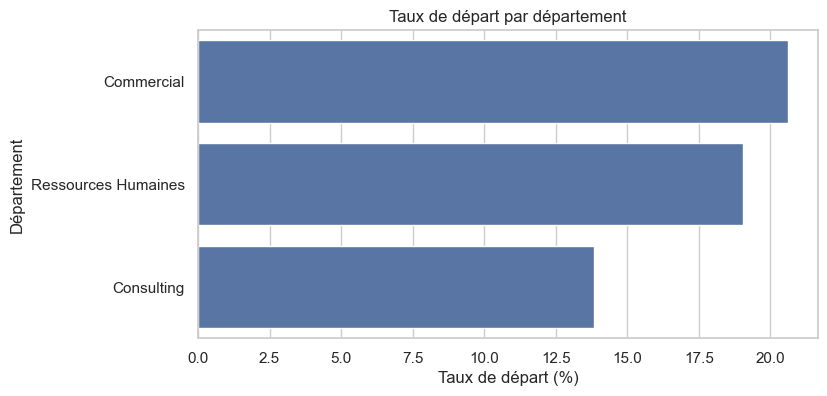

a_quitte_l_entreprise,departement,Non,Oui
0,Commercial,79.37,20.63
1,Ressources Humaines,80.95,19.05
2,Consulting,86.16,13.84


In [17]:
# Graphique 3 — Taux de départ par département
taux_departement = taux_depart_par_modalite(df_central, "departement").reset_index()

plt.figure(figsize=(8, 4))
sns.barplot(data=taux_departement, y="departement", x="Oui", orient="h")
plt.title("Taux de départ par département")
plt.xlabel("Taux de départ (%)")
plt.ylabel("Département")
plt.show()

display(taux_departement)


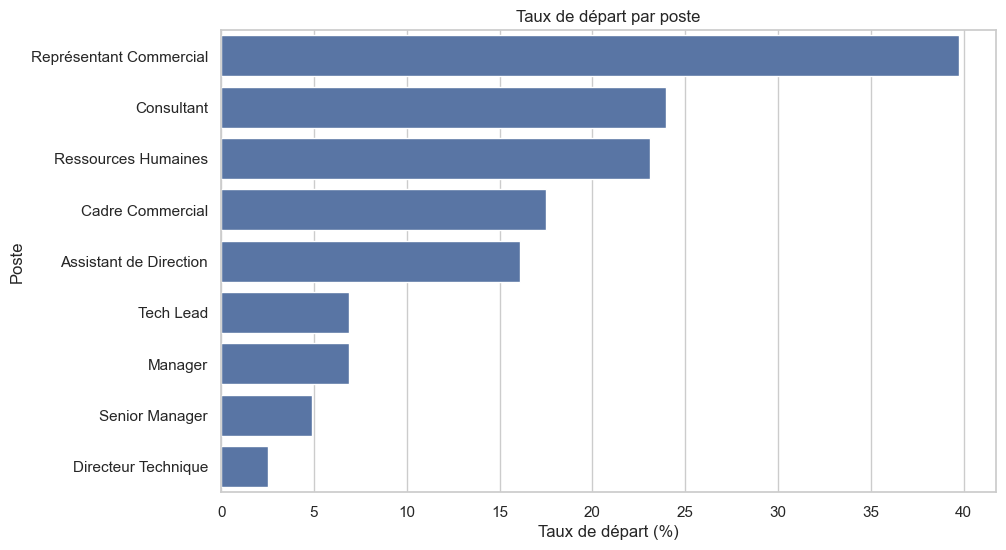

a_quitte_l_entreprise,poste,Non,Oui
0,Représentant Commercial,60.24,39.76
1,Consultant,76.06,23.94
2,Ressources Humaines,76.92,23.08
3,Cadre Commercial,82.52,17.48
4,Assistant de Direction,83.90,16.10
5,Tech Lead,93.10,6.90
6,Manager,93.13,6.87
7,Senior Manager,95.10,4.90
8,Directeur Technique,97.50,2.50


In [18]:
# Graphique 4 — Taux de départ par poste
taux_poste = taux_depart_par_modalite(df_central, "poste").reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=taux_poste, y="poste", x="Oui", orient="h")
plt.title("Taux de départ par poste")
plt.xlabel("Taux de départ (%)")
plt.ylabel("Poste")
plt.show()

display(taux_poste)


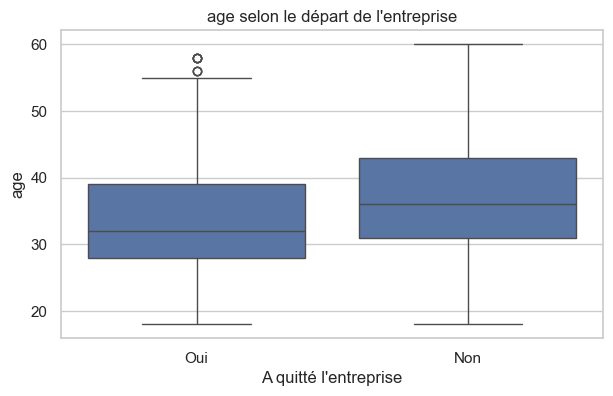

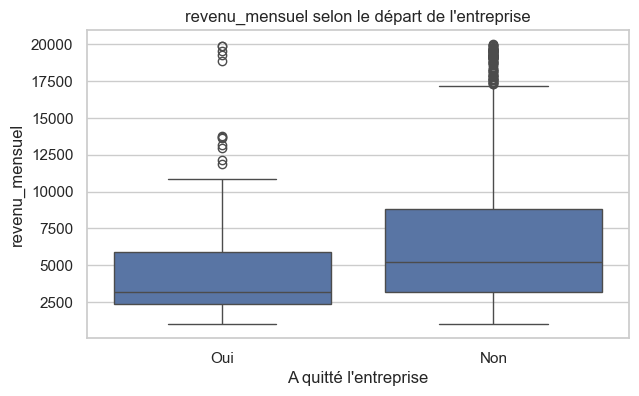

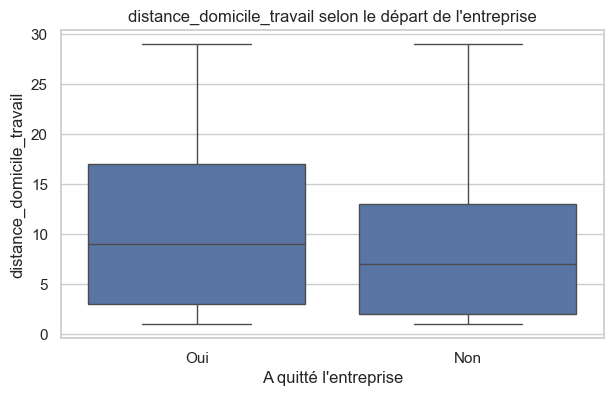

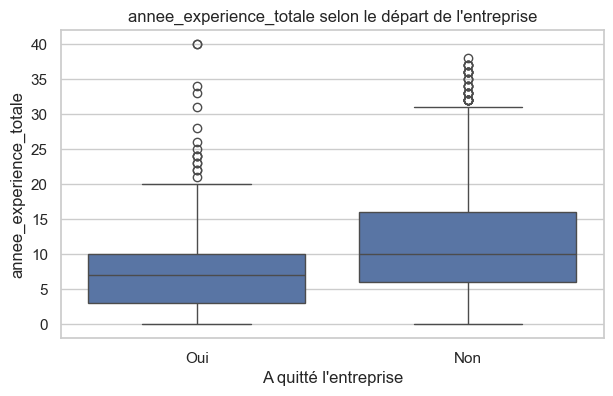

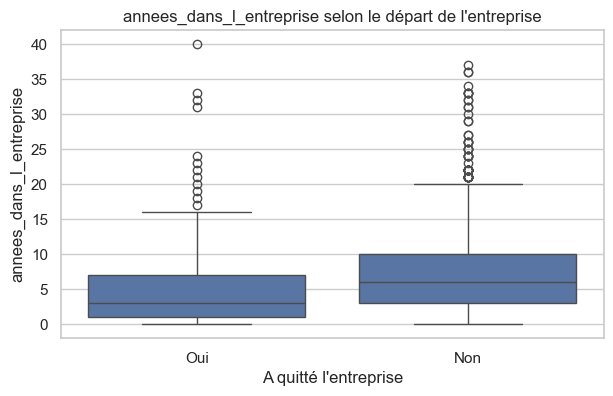

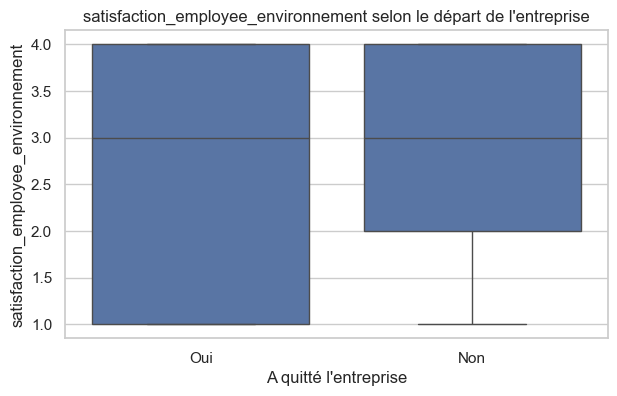

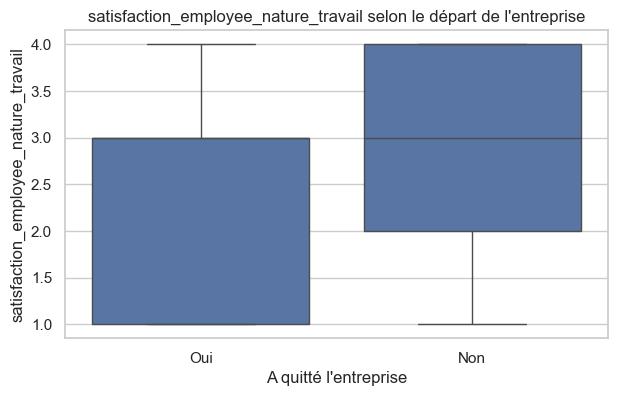

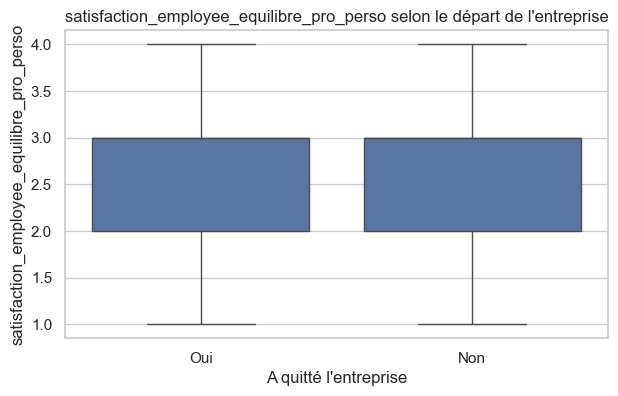

In [19]:
# Graphique 5 — Comparaison de variables numériques selon le départ
variables_boxplot = [
    "age",
    "revenu_mensuel",
    "distance_domicile_travail",
    "annee_experience_totale",
    "annees_dans_l_entreprise",
    "satisfaction_employee_environnement",
    "satisfaction_employee_nature_travail",
    "satisfaction_employee_equilibre_pro_perso",
]

for col in variables_boxplot:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df_central, x="a_quitte_l_entreprise", y=col)
    plt.title(f"{col} selon le départ de l'entreprise")
    plt.xlabel("A quitté l'entreprise")
    plt.ylabel(col)
    plt.show()


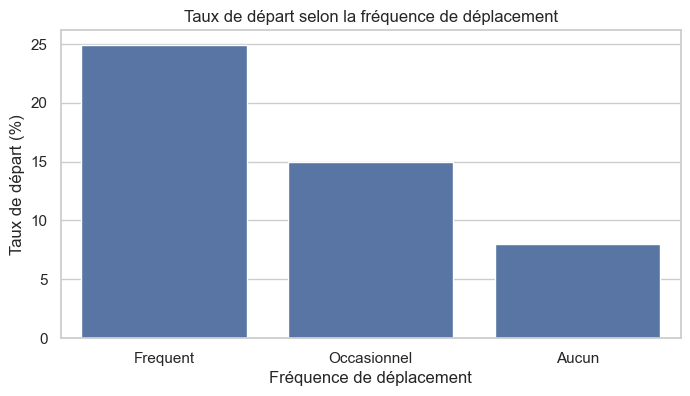

a_quitte_l_entreprise,frequence_deplacement,Non,Oui
0,Frequent,75.09,24.91
1,Occasionnel,85.04,14.96
2,Aucun,92.00,8.00


In [20]:
# Graphique 6 — Taux de départ selon la fréquence de déplacement
taux_deplacement = taux_depart_par_modalite(df_central, "frequence_deplacement").reset_index()

plt.figure(figsize=(8, 4))
sns.barplot(data=taux_deplacement, x="frequence_deplacement", y="Oui")
plt.title("Taux de départ selon la fréquence de déplacement")
plt.xlabel("Fréquence de déplacement")
plt.ylabel("Taux de départ (%)")
plt.show()

display(taux_deplacement)


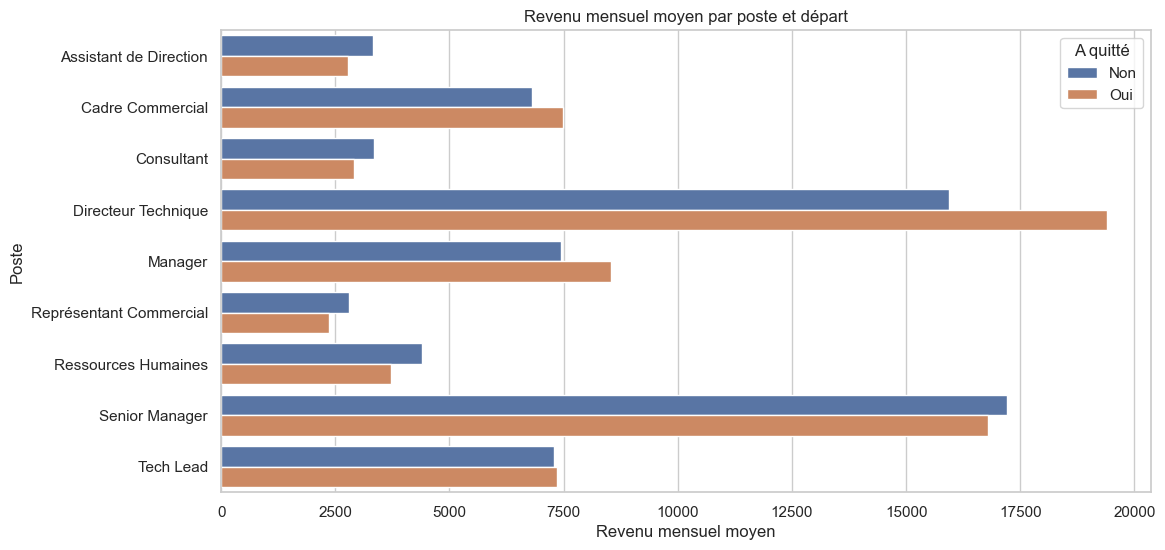

In [21]:
# Graphique 7 — Revenu mensuel moyen selon départ et poste
revenu_poste_attrition = (
    df_central
    .groupby(["poste", "a_quitte_l_entreprise"])["revenu_mensuel"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=revenu_poste_attrition,
    y="poste",
    x="revenu_mensuel",
    hue="a_quitte_l_entreprise",
    orient="h",
)
plt.title("Revenu mensuel moyen par poste et départ")
plt.xlabel("Revenu mensuel moyen")
plt.ylabel("Poste")
plt.legend(title="A quitté")
plt.show()


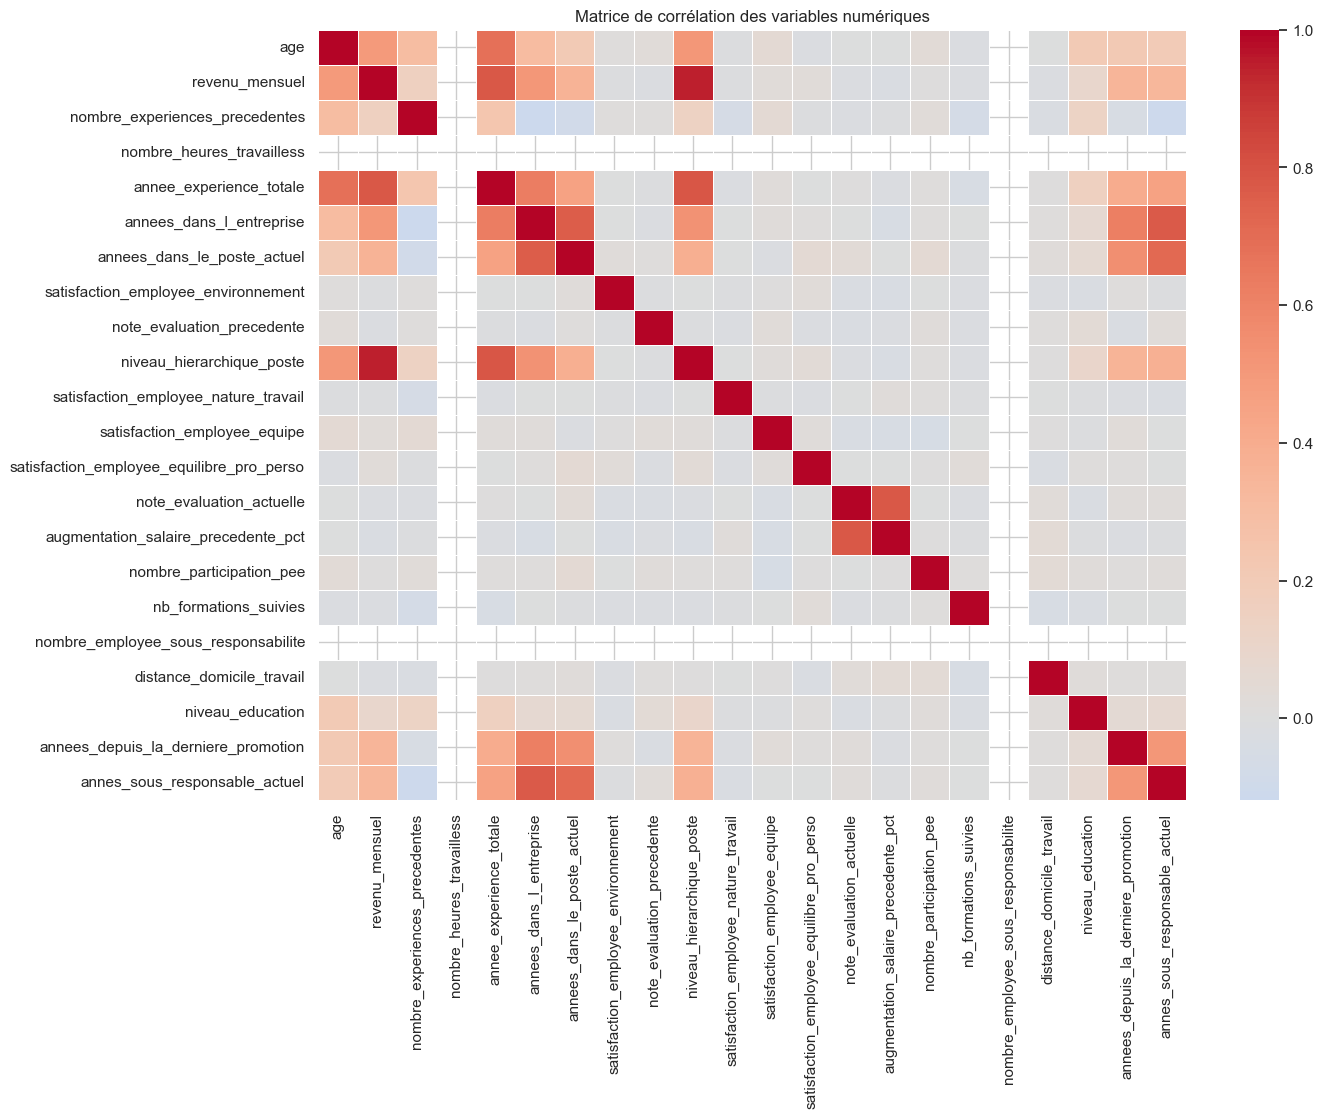

In [22]:
# Graphique 8 — Heatmap des corrélations numériques
plt.figure(figsize=(14, 10))
corr = df_central[colonnes_numeriques].corr(numeric_only=True)
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Matrice de corrélation des variables numériques")
plt.show()


## 7. Premières observations à commenter

À partir des tableaux et graphiques, commenter notamment :

- Le taux global de départ.
- Les variables catégorielles associées à un taux de départ élevé : heures supplémentaires, poste, département, fréquence de déplacement, statut marital.
- Les variables numériques qui différencient le plus les employés partis et restés : revenu mensuel, âge, expérience totale, ancienneté, distance domicile-travail et indicateurs de satisfaction.
- Les variables constantes ou peu informatives, par exemple celles avec une seule valeur unique.


In [23]:
# Aide à la rédaction : résumé automatique des différences les plus marquées

print("Taux global de départ :")
display(repartition_attrition)

print("\nTop 10 des écarts de moyenne numérique entre employés partis et restés :")
display(comparaison_moyennes.head(10))

print("\nTaux de départ par heures supplémentaires :")
display(taux_depart_par_modalite(df_central, "heure_supplementaires"))

print("\nTaux de départ par fréquence de déplacement :")
display(taux_depart_par_modalite(df_central, "frequence_deplacement"))

print("\nTaux de départ par poste :")
display(taux_depart_par_modalite(df_central, "poste"))


Taux global de départ :


,effectif,pourcentage
a_quitte_l_entreprise,,
Non,1233,83.88
Oui,237,16.12



Top 10 des écarts de moyenne numérique entre employés partis et restés :


a_quitte_l_entreprise,Non,Oui,ecart_oui_moins_non
revenu_mensuel,6832.74,4787.09,-2045.65
age,37.56,33.61,-3.95
annee_experience_totale,11.86,8.24,-3.62
annees_dans_l_entreprise,7.37,5.13,-2.24
distance_domicile_travail,8.92,10.63,1.72
annees_dans_le_poste_actuel,4.48,2.90,-1.58
annes_sous_responsable_actuel,4.37,2.85,-1.52
niveau_hierarchique_poste,2.15,1.64,-0.51
nombre_participation_pee,0.85,0.53,-0.32
satisfaction_employee_nature_travail,2.78,2.47,-0.31



Taux de départ par heures supplémentaires :


a_quitte_l_entreprise,Non,Oui
heure_supplementaires,,
Oui,69.47,30.53
Non,89.56,10.44



Taux de départ par fréquence de déplacement :


a_quitte_l_entreprise,Non,Oui
frequence_deplacement,,
Frequent,75.09,24.91
Occasionnel,85.04,14.96
Aucun,92.00,8.00



Taux de départ par poste :


a_quitte_l_entreprise,Non,Oui
poste,,
Représentant Commercial,60.24,39.76
Consultant,76.06,23.94
Ressources Humaines,76.92,23.08
Cadre Commercial,82.52,17.48
Assistant de Direction,83.90,16.10
Tech Lead,93.10,6.90
Manager,93.13,6.87
Senior Manager,95.10,4.90
Directeur Technique,97.50,2.50
